In [4]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple, Union

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [10]:
@dataclass(frozen=True)
class CouplingPlotConfig:
    period: str = "2012-2013"
    lags_name: str = "lag"  # dimension name in saved files
    ref_label: str = "REF_OLR_ERA5"
    title: str = "MJO coupling: OLR–U850 lag correlation (20–100 day bandpass, 10°S–10°N, 60–150°E)"
    xlim: Tuple[int, int] = (-20, 20)
    ylim: Optional[Tuple[float, float]] = (-0.6, 0.2)
    show_zero_lines: bool = True
    legend_ncol: int = 3
    figsize: Tuple[float, float] = (8, 6)
    dpi: int = 200


# -----------------------------
# Plotter
# -----------------------------
class MJOCouplingPlotter:
    """
    Read and plot coupling diagnostics saved as one NetCDF per experiment.

    Expected files:
      mjo_coupling_OLR_U850_REF_<period>.nc   (contains variable 'REF_OLR_ERA5' by default)
      mjo_coupling_OLR_U850_<EXP>_<period>.nc (contains variable named '<EXP>' by default)

    Robustness:
      - If variable name differs, it will pick the first data variable in the file.
      - Works whether data is saved as DataArray or Dataset with one variable.
    """

    def __init__(
        self,
        diag_dir: Union[str, Path],
        exp_list: Sequence[str],
        cfg: Optional[CouplingPlotConfig] = None,
        file_prefix: str = "mjo_coupling_OLR_U850",
    ):
        self.diag_dir = Path(diag_dir)
        self.exp_list = list(exp_list)
        self.cfg = cfg or CouplingPlotConfig()
        self.file_prefix = file_prefix

    # ---------- I/O ----------
    def _file_for(self, exp: str) -> Path:
        return self.diag_dir / f"{self.file_prefix}_{exp}_{self.cfg.period}.nc"

    def _open_curve(self, path: Path, expected_var: Optional[str] = None) -> xr.DataArray:
        ds = xr.open_dataset(path)

        # pick variable
        if expected_var is not None and expected_var in ds.data_vars:
            da = ds[expected_var]
        else:
            # fallback: first data var
            if len(ds.data_vars) == 0:
                raise ValueError(f"No data variables found in {path}")
            da = ds[list(ds.data_vars)[0]]

        # ensure lag coordinate exists
        if self.cfg.lags_name not in da.dims and self.cfg.lags_name in da.coords:
            # ok (coord-only)
            pass
        elif self.cfg.lags_name not in da.dims:
            raise ValueError(
                f"Expected dim '{self.cfg.lags_name}' not found in {path}. "
                f"Found dims={da.dims}"
            )

        return da

    def load_all_curves(self) -> Dict[str, xr.DataArray]:
        out: Dict[str, xr.DataArray] = {}

        # REF
        ref_path = self._file_for("REF")
        if not ref_path.exists():
            raise FileNotFoundError(f"Missing REF file: {ref_path}")
        out["REF"] = self._open_curve(ref_path, expected_var=self.cfg.ref_label)

        # experiments
        for exp in self.exp_list:
            p = self._file_for(exp)
            if not p.exists():
                print(f"[WARN] missing: {p} (skip)")
                continue
            out[exp] = self._open_curve(p, expected_var=exp)

        return out

    # ---------- summary metrics ----------
    @staticmethod
    def summarize_curve(da: xr.DataArray) -> Dict[str, float]:
        """
        Return simple scalar metrics:
          - min_corr
          - lag_at_min
          - corr_at_lag0 (if exists)
        """
        lag_name = "lag" if "lag" in da.dims else da.dims[0]
        lag = da[lag_name].values

        y = da.values
        i_min = int(np.nanargmin(y))
        min_corr = float(y[i_min])
        lag_at_min = float(lag[i_min])

        # lag0
        corr0 = np.nan
        if np.any(lag == 0):
            corr0 = float(y[np.where(lag == 0)[0][0]])

        return {"min_corr": min_corr, "lag_at_min": lag_at_min, "corr_lag0": corr0}

    def summarize_all(self, curves: Dict[str, xr.DataArray]) -> Dict[str, Dict[str, float]]:
        return {k: self.summarize_curve(v) for k, v in curves.items()}

    # ---------- plotting ----------
    def plot_overlay(
        self,
        curves: Optional[Dict[str, xr.DataArray]] = None,
        out_png: Optional[Union[str, Path]] = None,
        show: bool = True,
    ):
        if curves is None:
            curves = self.load_all_curves()

        cfg = self.cfg
        fig, ax = plt.subplots(figsize=cfg.figsize, dpi=cfg.dpi)

        # REF first (thicker)
        ref = curves.get("REF", None)
        if ref is None:
            raise ValueError("REF curve not found in curves dict.")

        ax.plot(ref[cfg.lags_name], ref, linewidth=2.8, label="REF (NOAA OLR vs ERA5 U850)")

        # experiments
        for exp in self.exp_list:
            if exp not in curves:
                continue
            da = curves[exp]
            ax.plot(da[cfg.lags_name], da, linewidth=1.6, label=exp)

        if cfg.show_zero_lines:
            ax.axhline(0, linewidth=0.8)
            ax.axvline(0, linewidth=0.8)

        ax.set_title(cfg.title)
        ax.set_xlabel("Lag (days): positive = U850 lags OLR")
        ax.set_ylabel("Correlation")
        ax.set_xlim(*cfg.xlim)
        if cfg.ylim is not None:
            ax.set_ylim(*cfg.ylim)

        ax.grid(True, linewidth=0.4, alpha=0.6)
        ax.legend(frameon=False, ncol=cfg.legend_ncol)

        fig.tight_layout()

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, bbox_inches="tight")
            print(f"Wrote: {out_png}")

        if show:
            plt.show()
        else:
            plt.close(fig)

    def plot_summary_minimum(
        self,
        curves: Optional[Dict[str, xr.DataArray]] = None,
        out_png: Optional[Union[str, Path]] = None,
        show: bool = True,
    ):
        """
        Two-panel summary:
          (a) min correlation per experiment
          (b) lag at min correlation per experiment
        """
        if curves is None:
            curves = self.load_all_curves()

        stats = self.summarize_all(curves)

        # order: REF then exp_list
        labels = ["REF"] + [e for e in self.exp_list if e in curves]
        min_corr = [stats[k]["min_corr"] for k in labels]
        lag_min = [stats[k]["lag_at_min"] for k in labels]

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), dpi=self.cfg.dpi)

        x = np.arange(len(labels))

        ax1.plot(x, min_corr, marker="o")
        ax1.set_xticks(x)
        ax1.set_xticklabels(labels, rotation=45, ha="right")
        ax1.set_ylabel("Min correlation")
        ax1.set_title("Coupling strength (more negative = stronger)")
        ax1.grid(True, linewidth=0.4, alpha=0.6)

        ax2.plot(x, lag_min, marker="o")
        ax2.set_xticks(x)
        ax2.set_xticklabels(labels, rotation=45, ha="right")
        ax2.set_ylabel("Lag at min (days)")
        ax2.set_title("Phase (positive = U850 lags OLR)")
        ax2.grid(True, linewidth=0.4, alpha=0.6)

        fig.suptitle(f"MJO coupling summary ({self.cfg.period})", y=1.02)
        fig.tight_layout()

        if out_png is not None:
            out_png = Path(out_png)
            out_png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, bbox_inches="tight")
            print(f"Wrote: {out_png}")

        if show:
            plt.show()
        else:
            plt.close(fig)


Wrote: fig_mjo_coupling_overlay_2012-2013.png


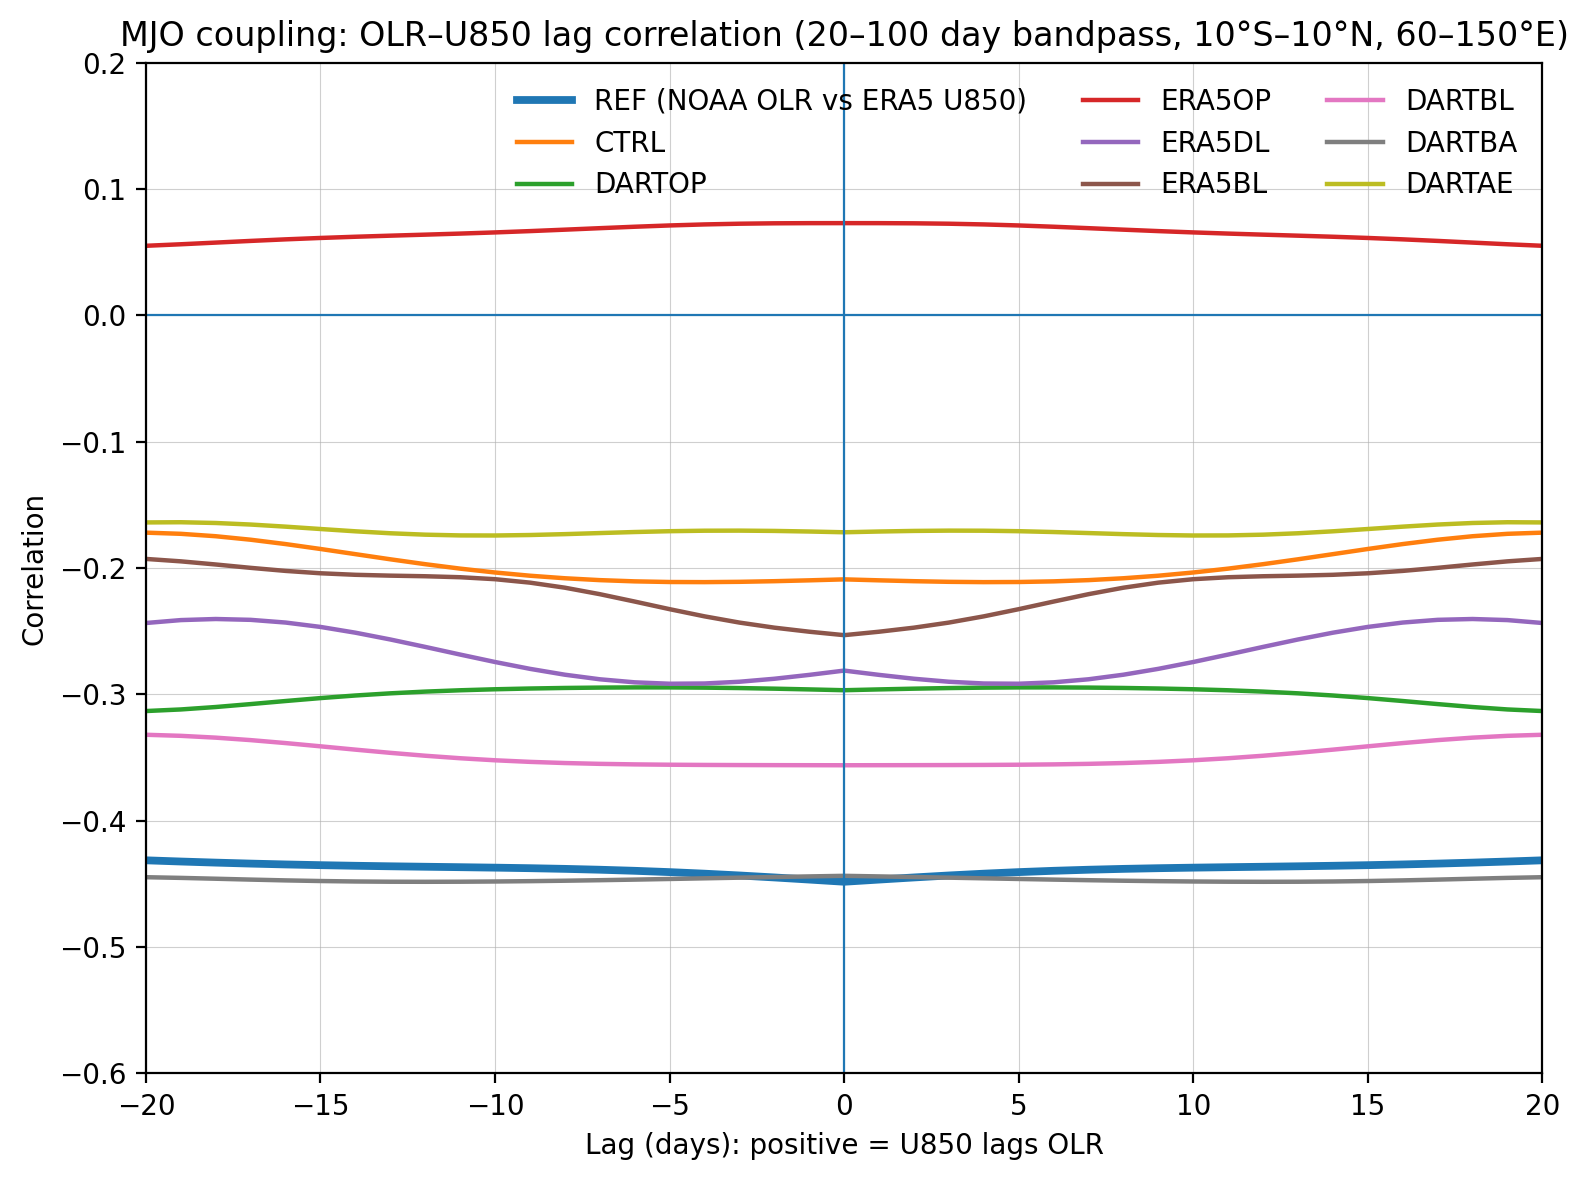

Wrote: fig_mjo_coupling_summary_2012-2013.png


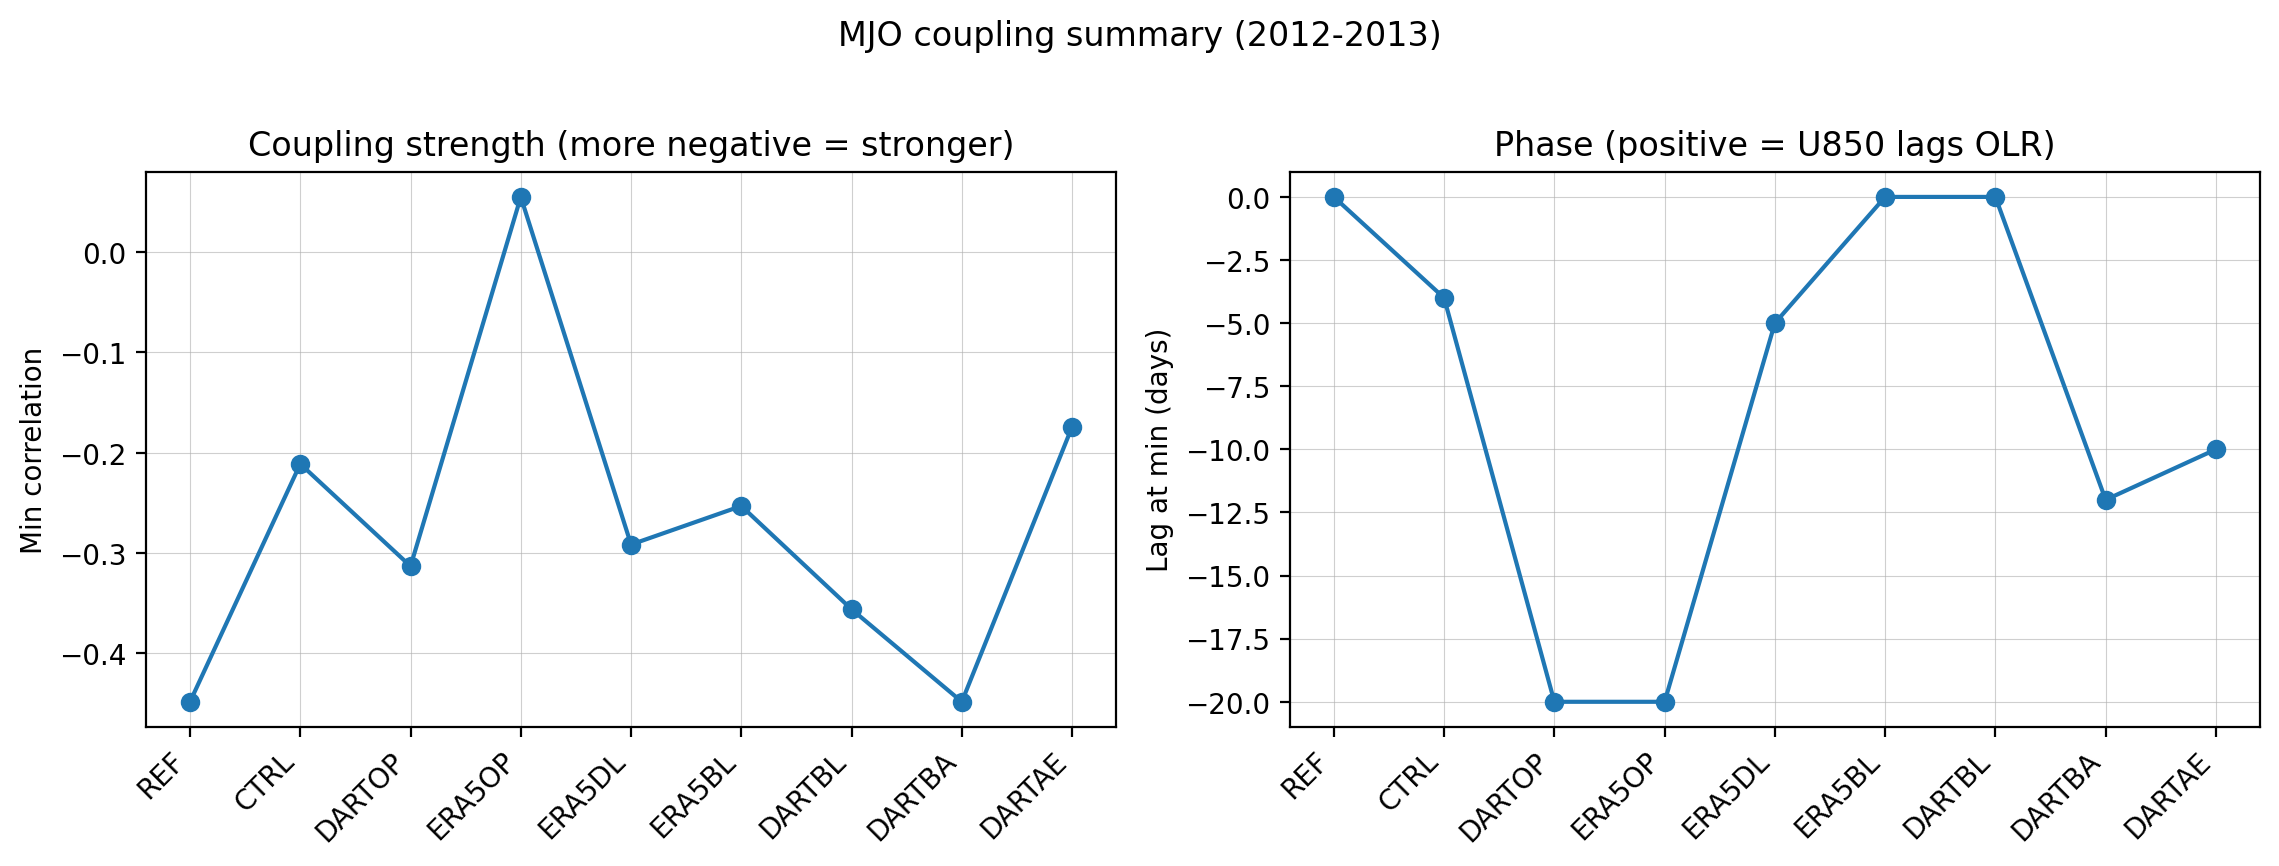

In [11]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    diag_dir = Path(work_dir) / "figure_data" / "mjo"
    fig_dir = "./"
    
    exp_list = ["CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE"]

    plotter = MJOCouplingPlotter(
        diag_dir=diag_dir,
        exp_list=exp_list,
        cfg=CouplingPlotConfig(period="2012-2013"),
    )

    curves = plotter.load_all_curves()

    # overlay (publication-style)
    plotter.plot_overlay(
        curves,
        out_png=Path(fig_dir) / "fig_mjo_coupling_overlay_2012-2013.png",
        show=True,
    )

    # compact summary
    plotter.plot_summary_minimum(
        curves,
        out_png=Path(fig_dir) / "fig_mjo_coupling_summary_2012-2013.png",
        show=True,
    )